In [ ]:
import pandas as pd
import numpy as np
import tensorflow as tf
from tensorflow.keras.utils import to_categorical
import matplotlib.pyplot as plt


In [ ]:
df = pd.read_csv("/content/drive/MyDrive/DATA PROJECT/Expertdemonstrartions.csv")

In [ ]:
df

,Row Position,Column Position,Reaction,Action
0,2,1,0,0
1,2,1,1,0
2,2,1,2,1
3,1,1,0,4
4,1,1,1,0
5,1,1,2,3
6,1,2,0,2
7,1,2,1,0
8,1,2,2,4
9,2,2,0,2


In [ ]:
actions =["sp","up","left","right","down"]

In [ ]:
def train_policy(expertDemonstration):
    df = expertDemonstration

    # state
    X= np.array(df[["Row Position","Column Position","Reaction"]])
    #actions
    y= np.array(df[["Action"]])
    #encodage oneHot de y
    y_oneHot_encoding = to_categorical(y)
    state_size= 3
    action_size = len(actions)
    # Define the model architecture
    policy = tf.keras.Sequential([
    tf.keras.layers.Input(shape=(state_size,)),
    tf.keras.layers.Dense(256, activation='relu'),
    tf.keras.layers.Dense(action_size, activation='softmax')
    ])

    # Define the optimizer and loss function
    optimizer = tf.keras.optimizers.Adam(learning_rate=0.1)

    # Train the model using imitation learning
    policy.compile(optimizer=optimizer, loss='categorical_crossentropy', metrics=['accuracy'])
    policy.summary()
    history = policy.fit(X, y_oneHot_encoding, validation_split=0.2, epochs=38, batch_size=64)
    # summarize history for accuracy
    plt.plot(history.history['accuracy'])
    plt.plot(history.history['val_accuracy'])
    plt.title('model accuracy')
    plt.ylabel('accuracy')
    plt.xlabel('epoch')
    plt.legend(['train','validation'], loc='upper left')
    plt.show()

    plt.plot(history.history['loss'])
    plt.plot(history.history['val_loss'])
    plt.title('model loss')
    plt.ylabel('loss')
    plt.xlabel('epoch')
    plt.legend(['train', 'validation'], loc='upper left')
    plt.show()

    return policy

Model: "sequential"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 dense (Dense)               (None, 256)               1024      
                                                                 
 dense_1 (Dense)             (None, 5)                 1285      
                                                                 
Total params: 2,309
Trainable params: 2,309
Non-trainable params: 0
_________________________________________________________________
Epoch 1/38
1/1 [==============================] - 1s 1s/step - loss: 1.6565 - accuracy: 0.1176 - val_loss: 5.7965 - val_accuracy: 0.4000
Epoch 2/38
1/1 [==============================] - 0s 37ms/step - loss: 4.5083 - accuracy: 0.4706 - val_loss: 1.2666 - val_accuracy: 0.6000
Epoch 3/38
1/1 [==============================] - 0s 56ms/step - loss: 1.1686 - accuracy: 0.7647 - val_loss: 1.7914 - val_accuracy: 0.6000
Epoch 4/38
1/1 [===================

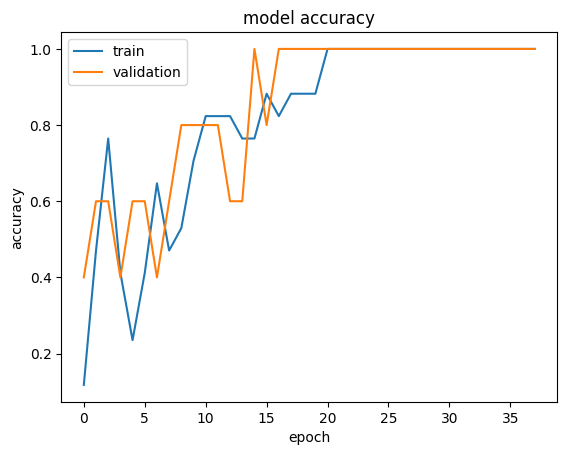

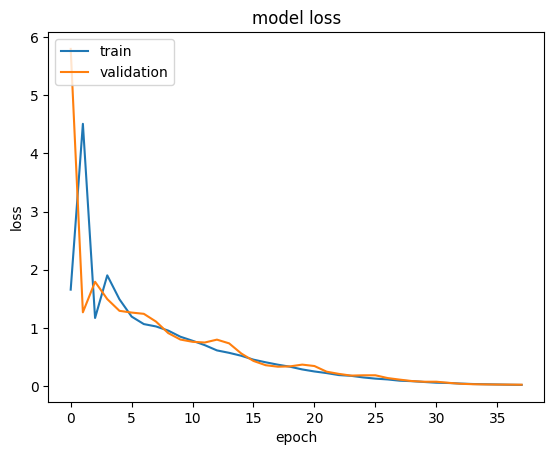

In [ ]:
model=train_policy(df)

Model: "sequential_1"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 dense_2 (Dense)             (None, 256)               1024      
                                                                 
 dense_3 (Dense)             (None, 5)                 1285      
                                                                 
Total params: 2,309
Trainable params: 2,309
Non-trainable params: 0
_________________________________________________________________
Epoch 1/38
1/1 [==============================] - 0s 340ms/step - loss: 1.6835 - accuracy: 0.0588 - val_loss: 5.8981 - val_accuracy: 0.4000
Epoch 2/38
1/1 [==============================] - 0s 20ms/step - loss: 4.7213 - accuracy: 0.4706 - val_loss: 1.2770 - val_accuracy: 0.4000
Epoch 3/38
1/1 [==============================] - 0s 24ms/step - loss: 1.1334 - accuracy: 0.5882 - val_loss: 1.6941 - val_accuracy: 0.4000
Epoch 4/38
1/1 [==============

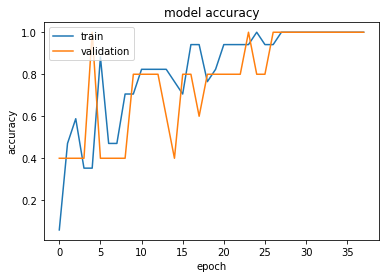

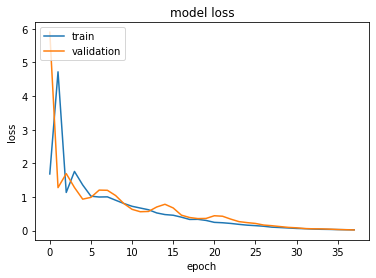

In [ ]:
model = train_policy(df)

In [ ]:
# This function returns the coordinates of the initial state
def get_starting_location():
    return 2,1

In [ ]:
# Function that chooses the next action using the trained policy
def get_next_action(current_row_index,current_column_index, reaction, model):
    probability_each_action= model.predict([[current_row_index,current_column_index,reaction]])
    return np.argmax(probability_each_action),probability_each_action

In [ ]:
prob=get_next_action(2,1, 1, model)

1/1 [==============================] - 0s 99ms/step


In [ ]:
# Function that determines whether we are in the final state
def is_terminal_state(current_row_index,current_column_index):
    if current_row_index ==2 and current_column_index == 2:
        return True
    else:
        return False

In [ ]:
# Function that selects the next state based on the action taken by the attacker
def get_next_location(current_row_index, current_column_index, action_index):
    new_row_index = current_row_index
    new_column_index = current_column_index
    if actions[action_index] == 'up' and current_row_index > 1 :
        new_row_index -= 1 # new_row_index = new_row_index -1
    elif actions[action_index] == 'right' and current_column_index < 2:
        new_column_index +=1
    elif actions[action_index] == 'down' and current_row_index < 2:
        new_row_index += 1

    elif actions[action_index] == 'left' and current_column_index > 1 :
        new_column_index -= 1
    return new_row_index, new_column_index

In [ ]:
get_next_location(1, 2, 1)

(1, 2)

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
# Function that defines the shortest path the attacker should take to scam the victim
def get_shortest_path(start_row_index, start_column_index):
    # Returns whether the initial state is invalid
    if is_terminal_state(start_row_index, start_column_index):
        return []
    else:
        cpt=0
        current_row_index, current_column_index = start_row_index, start_column_index
        shortest_path = []
        shortest_path.append([current_row_index, current_column_index])
       # Continue transitioning from one state to the next until the final state is reached
        while (not is_terminal_state(current_row_index, current_column_index)):
            # We assume that the environment is more likely to return a favorable outcome for the victim
            reaction = np.argmax(np.random.multinomial(1,np.array([2,3,15])/16,1)[0])
         # Returns the best action to take
            action_index, plb = get_next_action(current_row_index, current_column_index, reaction,model)
            print("x={} , y={} ,reaction={}------->action={},probability={}".format(current_row_index, current_column_index,reaction,actions[action_index],plb))
           # Moves to the next state and adds the new state to the list
            current_row_index, current_column_index = get_next_location(current_row_index, current_column_index, action_index)
            shortest_path.append([current_row_index, current_column_index])
            cpt=cpt+1
        return shortest_path

In [ ]:
get_shortest_path(2, 1)

1/1 [==============================] - 0s 218ms/step
x=2 , y=1 ,reaction=1------->action=sp,probability=[[9.9927777e-01 7.2199595e-04 5.6925953e-12 8.9494641e-11 2.1563955e-07]]
1/1 [==============================] - 0s 177ms/step
x=2 , y=1 ,reaction=2------->action=up,probability=[[7.2439230e-04 9.9881196e-01 2.2855225e-19 4.6298810e-04 6.7254501e-07]]
1/1 [==============================] - 0s 114ms/step
x=1 , y=1 ,reaction=1------->action=sp,probability=[[9.8884165e-01 8.4158889e-04 4.0062861e-08 1.4206811e-05 1.0302527e-02]]
1/1 [==============================] - 0s 224ms/step
x=1 , y=1 ,reaction=0------->action=down,probability=[[2.0889983e-02 2.9621510e-09 2.6283735e-02 5.9115972e-12 9.5282626e-01]]
1/1 [==============================] - 0s 66ms/step
x=2 , y=1 ,reaction=0------->action=sp,probability=[[9.8465341e-01 5.7741369e-07 2.9631227e-04 3.9819544e-14 1.5049744e-02]]
1/1 [==============================] - 0s 202ms/step
x=2 , y=1 ,reaction=0------->action=sp,probability=[[9.8

[[2, 1],
 [2, 1],
 [1, 1],
 [1, 1],
 [2, 1],
 [2, 1],
 [2, 1],
 [1, 1],
 [1, 2],
 [2, 2]]

In [ ]:
actions

['sp', 'up', 'left', 'right', 'down']

Model: "sequential_2"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 dense_4 (Dense)             (None, 256)               1024      
                                                                 
 dense_5 (Dense)             (None, 5)                 1285      
                                                                 
Total params: 2,309
Trainable params: 2,309
Non-trainable params: 0
_________________________________________________________________
Epoch 1/38
1/1 [==============================] - 0s 441ms/step - loss: 1.5626 - accuracy: 0.2941 - val_loss: 5.7310 - val_accuracy: 0.4000
Epoch 2/38
1/1 [==============================] - 0s 22ms/step - loss: 4.3759 - accuracy: 0.4706 - val_loss: 1.5494 - val_accuracy: 0.0000e+00
Epoch 3/38
1/1 [==============================] - 0s 23ms/step - loss: 1.3300 - accuracy: 0.4706 - val_loss: 1.5563 - val_accuracy: 0.6000
Epoch 4/38
1/1 [==========

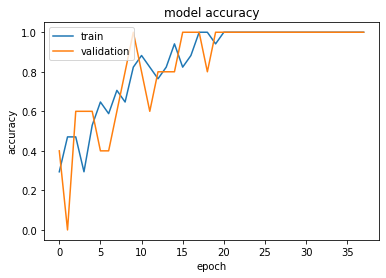

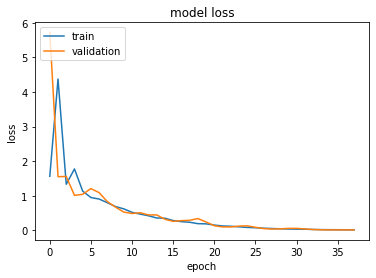

In [ ]:
train_policy(df)